Netflix Movies and TV Shows Analysis

### Exploratory Data Analysis Using Python

**Objective:** To analyze Netflix's content library and discover trends in movies, TV shows, countries, and release years.

In [ ]:
# IMPORTING REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# NETFLIX MOVIES AND TV SHOWS ANALYSIS

## PROJECT OBJECTIVE

The objective of this project is to analyze Netflix Movies and TV Shows data to understand content distribution, missing values, content types, release years, countries, and popular genres.

In [ ]:
# LOADING THE DATASET
df= pd.read_csv(r"C:\Users\pranav\Downloads\archive (3)\netflix_titles.csv")
df
print("DATASET LOADED SUCCESSFULLY")
display(df.head(10))

print("DATASET SHAPE:", df.shape)

DATASET LOADED SUCCESSFULLY


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


DATASET SHAPE: (8807, 12)


# DATASET OVERVIEW

This section provides an overview of the Netflix dataset, including the first few records, number of rows and columns, column names, and data types.et.s.

In [26]:
# CHECKING DATASET INFORMATION

print("DATASET INFORMATION")
df.info()

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATASET SHAPE")
print(df.shape)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

COLUMN NAMES
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

DATASET SHAPE
(8807, 12)


In [27]:
# CHECKING MISSING VALUES

print("MISSING VALUES IN EACH COLUMN")
print(df.isnull().sum())

print("\nMISSING VALUES PERCENTAGE")
print((df.isnull().mean() * 100).round(2))

MISSING VALUES IN EACH COLUMN
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

MISSING VALUES PERCENTAGE
show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64


# DATA CLEANING AND PREPROCESSING

This section handles missing values, converts the date_added column into datetime format, and removes duplicate records to improve data quality.s.

In [28]:
# DATA CLEANING

# FILLING MISSING VALUES IN TEXT COLUMNS
for col in ['director', 'cast', 'country']:
    df[col] = df[col].fillna('Unknown')

# FILLING MISSING RATING VALUES WITH MODE
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

# CONVERTING DATE COLUMN TO DATETIME
df['date_added'] = pd.to_datetime(
    df['date_added'],
    format='mixed',
    errors='coerce'
)

# CHECKING DUPLICATES BEFORE REMOVING THEM
print("DUPLICATE ROWS BEFORE CLEANING:", df.duplicated().sum())

# REMOVING DUPLICATES
df = df.drop_duplicates()

print("DATASET SHAPE AFTER CLEANING:", df.shape)

# CHECKING REMAINING MISSING VALUES
print("\nREMAINING MISSING VALUES")
print(df.isnull().sum())

DUPLICATE ROWS BEFORE CLEANING: 0
DATASET SHAPE AFTER CLEANING: (8807, 12)

REMAINING MISSING VALUES
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


In [29]:
# DESCRIPTIVE STATISTICS

print("DESCRIPTIVE STATISTICS")
display(df.describe(include='all').T)

print("\nUNIQUE VALUES IN EACH COLUMN")
print(df.nunique())

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8807,4529,Unknown,2634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,8807,7693,Unknown,825,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8807,749,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,NaN,NaN,NaN,2019-05-17 05:59:08.436967168,2008-01-01 00:00:00,2018-04-06 00:00:00,2019-07-02 00:00:00,2020-08-19 00:00:00,2021-09-25 00:00:00,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,1925.0,2013.0,2017.0,2019.0,2021.0,8.819312
rating,8807,17,TV-MA,3211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN



UNIQUE VALUES IN EACH COLUMN
show_id         8807
type               2
title           8807
director        4529
cast            7693
country          749
date_added      1714
release_year      74
rating            17
duration         220
listed_in        514
description     8775
dtype: int64


# EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is performed to identify patterns and trends in the Netflix dataset using visualizations and summary statistics.

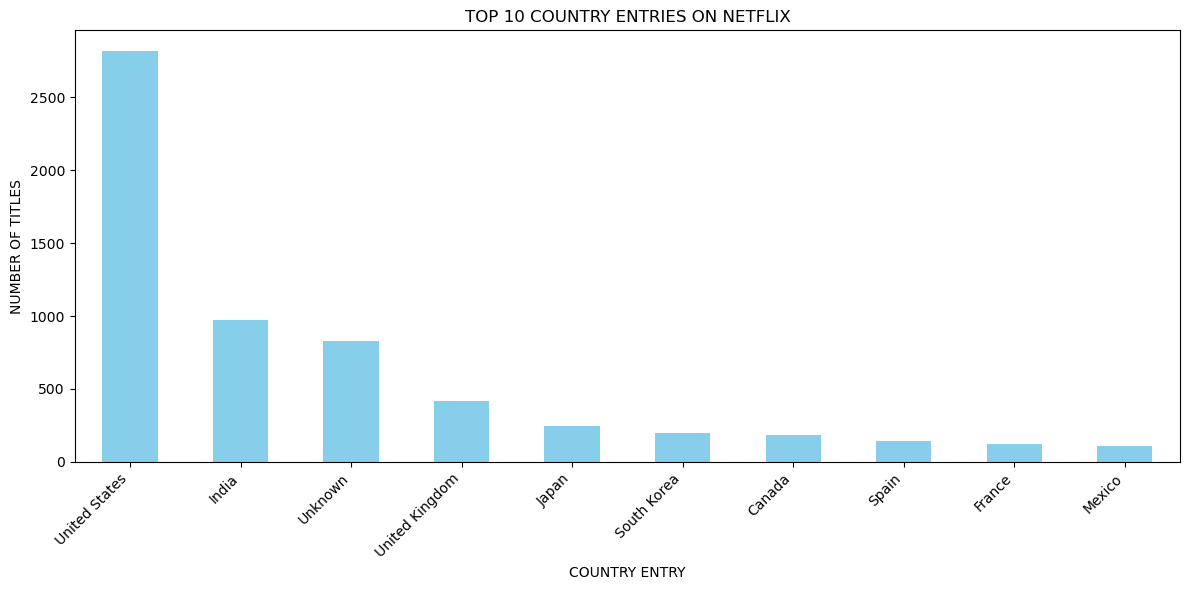

In [30]:
# TOP 10 COUNTRY ENTRIES

country_counts = df['country'].value_counts().head(10)

plt.figure(figsize=(12, 6))
country_counts.plot(kind='bar', color='skyblue')

plt.title('TOP 10 COUNTRY ENTRIES ON NETFLIX')
plt.xlabel('COUNTRY ENTRY')
plt.ylabel('NUMBER OF TITLES')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

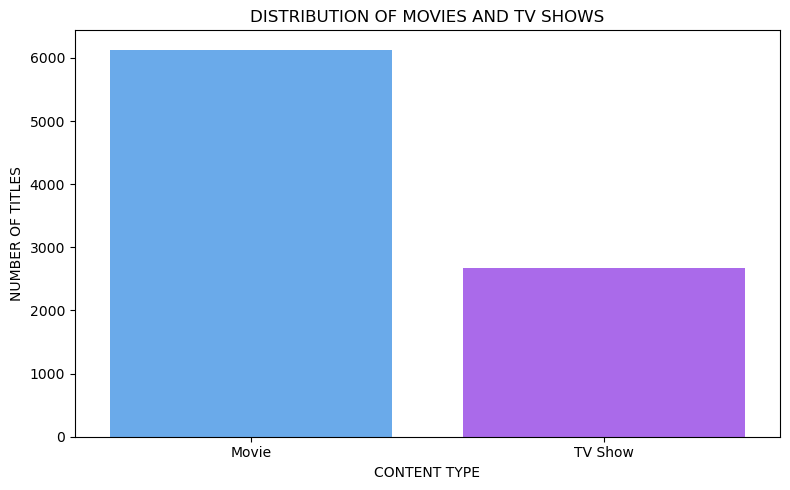

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [31]:
# DISTRIBUTION OF MOVIES AND TV SHOWS

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='type', hue='type', palette='cool', legend=False)

plt.title('DISTRIBUTION OF MOVIES AND TV SHOWS')
plt.xlabel('CONTENT TYPE')
plt.ylabel('NUMBER OF TITLES')
plt.tight_layout()
plt.show()

print(df['type'].value_counts())

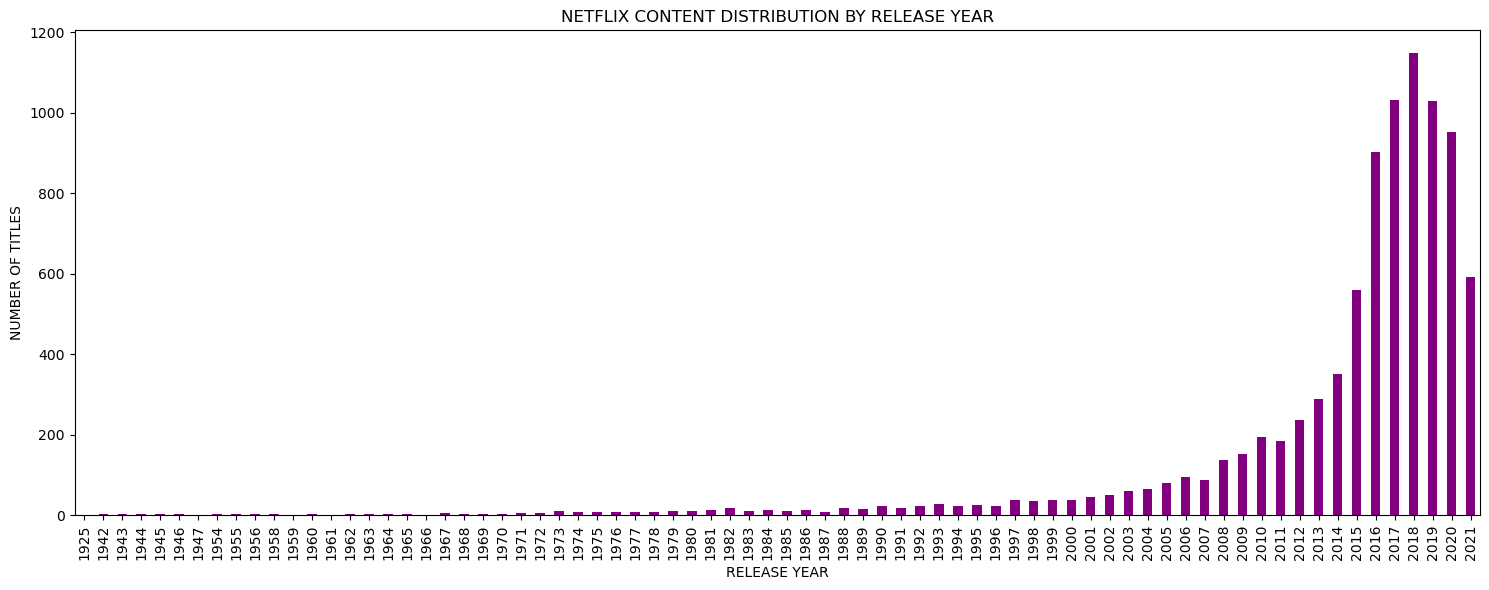

In [32]:
# CONTENT DISTRIBUTION BY RELEASE YEAR

release_counts = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(15, 6))
release_counts.plot(kind='bar', color='purple')

plt.title('NETFLIX CONTENT DISTRIBUTION BY RELEASE YEAR')
plt.xlabel('RELEASE YEAR')
plt.ylabel('NUMBER OF TITLES')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

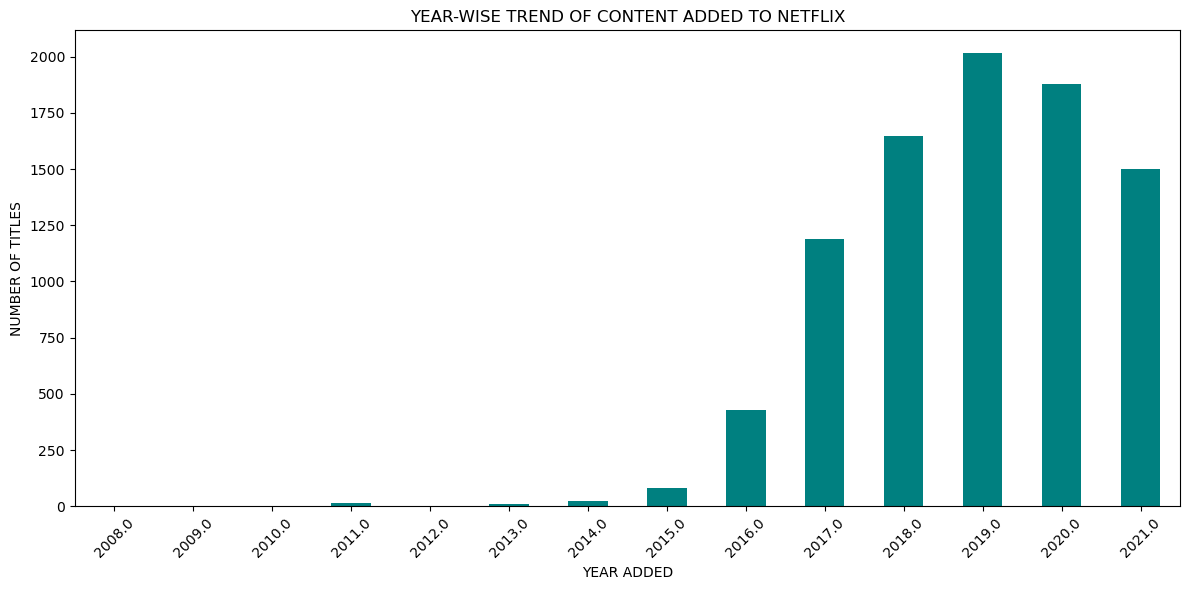

In [33]:
# YEAR-WISE TREND OF CONTENT ADDED TO NETFLIX

df['year_added'] = df['date_added'].dt.year

yearly_counts = df['year_added'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
yearly_counts.plot(kind='bar', color='teal')

plt.title('YEAR-WISE TREND OF CONTENT ADDED TO NETFLIX')
plt.xlabel('YEAR ADDED')
plt.ylabel('NUMBER OF TITLES')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

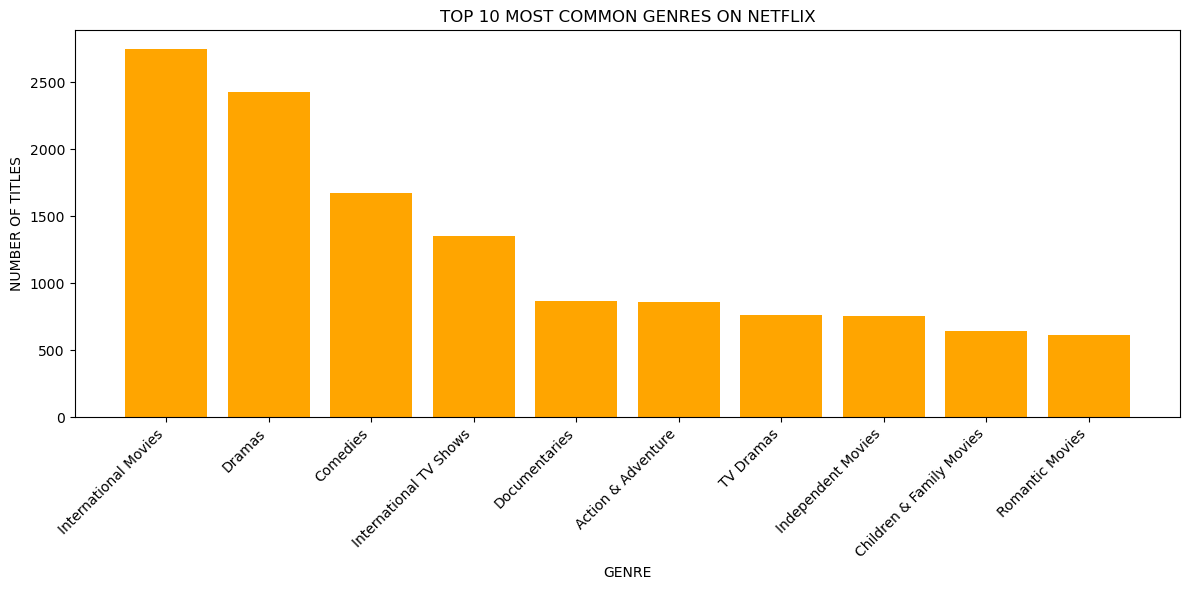

In [34]:
# TOP 10 MOST COMMON GENRES ON NETFLIX

genre_list = df['listed_in'].dropna().str.split(', ')
all_genres = [genre.strip() for genres in genre_list for genre in genres]

genre_counts = Counter(all_genres)
top_genres = genre_counts.most_common(10)

genres = [item[0] for item in top_genres]
counts = [item[1] for item in top_genres]

plt.figure(figsize=(12, 6))
plt.bar(genres, counts, color='orange')

plt.title('TOP 10 MOST COMMON GENRES ON NETFLIX')
plt.xlabel('GENRE')
plt.ylabel('NUMBER OF TITLES')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# KEY FINDINGS AND CONCLUSION

## KEY FINDINGS

- The dataset contains information about Netflix movies and TV shows.
- Missing values were handled during data cleaning.
- Duplicate records were checked and removed.
- Visualizations were used to compare movies and TV shows.
- Release-year and content-added trends were explored.
- The most common genres were identified using genre counts.
- Country entries were analyzed to understand content distribution.

## CONCLUSION

This project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn can be used for data cleaning, exploratory data analysis, and visualization. The analysis helps identify patterns in Netflix's content catalogue and presents the findings through graphical representations.

In [35]:
# FINAL PROJECT SUMMARY

print("NETFLIX DATA ANALYSIS")
print("-" * 40)

print("TOTAL TITLES:", len(df))

print("\nCONTENT TYPE DISTRIBUTION")
print(df['type'].value_counts())

print("\nDUPLICATE ROWS REMAINING:", df.duplicated().sum())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nPROJECT COMPLETED SUCCESSFULLY")

NETFLIX DATA ANALYSIS
----------------------------------------
TOTAL TITLES: 8807

CONTENT TYPE DISTRIBUTION
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

DUPLICATE ROWS REMAINING: 0

MISSING VALUES
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
year_added      10
dtype: int64

PROJECT COMPLETED SUCCESSFULLY
